<a href="https://www.kaggle.com/code/makrrc/0-91964-v10-s0511-predicting-loan-payback?scriptVersionId=280386684" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

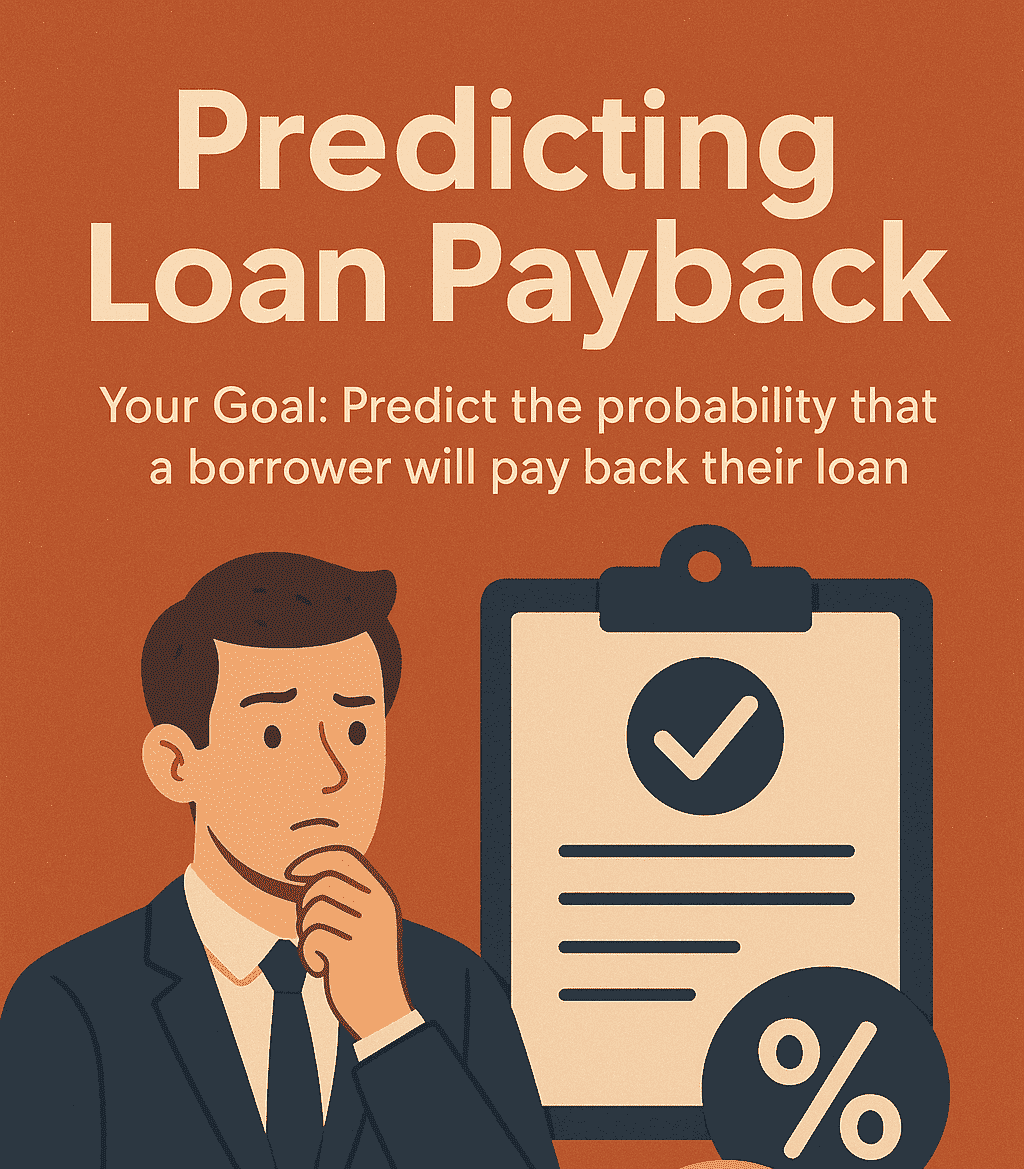

Estou colocando aqui os dados das colunas do Dataset original para ajudar na pesquisa:

age (int64) – Borrower's age (in years).
idade (int64) – Idade do mutuário (em anos).

gender (category) – Borrower's gender (Male/Female).
gênero (categoria) – Gênero do tomador do empréstimo (Masculino/Feminino).

marital_status (category) – Marital status (Single, Married, Divorced).
marital_status (categoria) – Estado civil (Solteiro(a), Casado(a), Divorciado(a)).

education_level (category) – Education level (High School, Bachelor, Master, PhD).
nível_de_educação (categoria) – Nível de escolaridade (Ensino Médio, Bacharelado, Mestrado, Doutorado).

2. Financial Information

annual_income (float64) – Borrower's yearly income.
annual_income (float64) – Renda anual do mutuário.

monthly_income (float64) – Borrower's monthly income.
monthly_income (float64) – Renda mensal do mutuário.

employment_status (category) – Current employment type (Employed, Self-Employed, Unemployed).
employment_status (categoria) – Tipo de emprego atual (Empregado, Autônomo, Desempregado).


debt_to_income_ratio (float64) – Ratio of borrower’s debt to their income. Lower = better.
índice_dívida_em_renda (float64) – Proporção entre a dívida do mutuário e sua renda. Quanto menor, melhor.


credit_score (int64) – Credit bureau score (e.g., FICO). Higher = less risky.
credit_score (int64) – Pontuação de crédito (ex.: FICO). Quanto maior, menor o risco.

3. Loan Information
3. Informações sobre o empréstimo

loan_amount (float64) – Amount of loan taken.
loan_amount (float64) – Valor do empréstimo contraído.

loan_purpose (category) – Loan purpose (Car, Education, Home, Medical, etc.).
loan_purpose (category) – Finalidade do empréstimo (Carro, Educação, Casa, Médico, etc.).

interest_rate (float64) – Loan par annual interest rate (%).
taxa_de_juros (float64) – Taxa de juros anual nominal do empréstimo (%).

loan_term (int64) – Loan repayment duration (months, e.g., 36 or 60).
loan_term (int64) – Duração do reembolso do empréstimo (em meses, por exemplo, 36 ou 60).

installment (float64) – Monthly installment.
Parcela (float64) – Parcela mensal.

--------

grade_subgrade (category) – Risk category assigned to loan (A1, B2, etc.).
grade_subgrade (categoria) – Categoria de risco atribuída ao empréstimo (A1, B2, etc.).

4. Borrower’s Credit History
5. 4. Histórico de crédito do mutuário

num_of_open_accounts (int64) – Total active credit accounts.
num_of_open_accounts (int64) – Total de contas de crédito ativas.

total_credit_limit (float64) – Borrower's total available credit limit.
total_credit_limit (float64) – Limite de crédito total disponível do mutuário.

current_balance (float64) – Borrower's outstanding balance (loan + credit card).
saldo_atual (float64) – Saldo devedor do mutuário (empréstimo + cartão de crédito).

delinquency_history (int64) – Count of late payments in borrower’s history.
delinquency_history (int64) – Número de pagamentos atrasados ​​no histórico do mutuário.

public_records (int64) – Negative public records (e.g., bankruptcies, legal actions).
public_records (int64) – Registros públicos negativos (por exemplo, falências, ações judiciais).

num_of_delinquencies (int64) – Total delinquencies (missed payments).
num_of_delinquencies (int64) – Total de inadimplências (pagamentos não efetuados).

5. Target Variable

loan_paid_back (int64) – Target variable:
loan_paid_back (int64) – Variável alvo:

1 → Borrower paid loan in full.
1 → O mutuário pagou o empréstimo integralmente.

0 → Borrower defaulted (did not repay fully).
0 → O devedor ficou inadimplente (não pagou o valor total da dívida).

In [ ]:
from sklearn.preprocessing import LabelEncoder

Load the training and testing databases. <br>
<hr>
Carregar as bases de treino e teste.

In [ ]:
train = pd.read_csv('/kaggle/input/playground-series-s5e11/train.csv')
test = pd.read_csv('/kaggle/input/playground-series-s5e11/test.csv')

Há uma idéia que é utilizar a base original para treinar um modelo  e treinar nos resíduos deste modelo como este artigo [aqui](https://www.kaggle.com/competitions/playground-series-s5e11/discussion/614986). Vamos ver se dá certo.

In [ ]:
oringin = pd.read_csv("/kaggle/input/loan-prediction-dataset-2025/loan_dataset_20000.csv")

Look the data to know the structure.

In [ ]:
train.head()

Look the stastistical data about datas its important to understand quickly.

<hr>

Analise os dados estatísticos, é importante compreendê-los rapidamente.

In [ ]:
train.describe()

Now. Look the data that's null into database.
<hr>
Agora, verifique os dados nulos no banco de dados.

In [ ]:
train.isna().sum()

Look data type of each column and make decisions according to your strategy.
<hr>
Analise o tipo de dados de cada coluna e tome decisões de acordo com sua estratégia.

In [ ]:
train.dtypes

The column genre has few possible values.
<hr>
A coluna gênero tem poucos possíveis valores. <br>

In [ ]:
train['gender'].unique()

With the command below, we saw that only 3 possible values ​​can occur.
Therefore, I decided to use the one-hot encoding method.
<hr>
Com o comando abaixo vimos que apenas 3 possíveis valores podem ocorrer. <br>
Por isto, decidi usar o método one hot encoding. <br>

In [ ]:
train[train['gender'] == 'Other']

Carregando o Label encoder.

In [ ]:
objList = train.select_dtypes(include = "object").columns
objList

A method for encoding columns passed as parameters by the LabelEncoder method. Suitable when there is a "hierarchy" or dependent linking pattern between data in the database.

Example: Low, medium, high.
<hr>
Método para codificar as colunas passadas como parâmetros pelo método LabelEncoder. Adequado quando há "hierarquia" ou forma de ligação dependente entre dados na base.

Exemplo: Baixo, médio, alto.

In [ ]:
le = LabelEncoder()
def CodificarLabelEncode(Dataset, columns, LabelEncoder):
    LabelEncoder.fit(Dataset[columns])
    Dataset['le_'+columns] = le.transform(Dataset[columns])
    return Dataset

In [ ]:
labelLists = ['marital_status', 'education_level']

In [ ]:
# for labelList in labelLists:
#     train = CodificarLabelEncode(train, labelList, le)

# train

Now let's create a function to generate features like OrdinalEncoder.
<hr>
Agora vamos criar uma função para gerar features com o OrdinalEncoder.

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

In [ ]:
# def CodificarOrdinalEncoder( Dataset, columns, OrdinalEncoder ):
#     OrdinalEncoder.fit(Dataset[columns])
#     Dataset['oe_'+columns] = le.transform(Dataset[[columns]])
#     return Dataset    

In [ ]:
oe = OrdinalEncoder()

def CodificarOrdinalEncoder(dataset, column, encoder):
    """
    Codifica uma coluna categórica usando OrdinalEncoder e
    adiciona uma nova coluna codificada ao DataFrame.
    """
    # O erro estava aqui: precisamos passar [[column]] para garantir 2D
    encoder.fit(dataset[[column]])  
    dataset['oe_' + column] = encoder.transform(dataset[[column]])
    return dataset

Let's create a function that performs the one-hot encoding procedure, just like in LabelEncoding.
<hr>
Vamos criar uma função que faz o procedimento de one Hot encoding igual o feito no LabelEncoding

In [ ]:
ordinalLists = ['marital_status', 'education_level']

In [ ]:
for ordinalList in ordinalLists:
    train = CodificarOrdinalEncoder(train, ordinalList, oe)

In [ ]:
for ordinalList in ordinalLists:
    test = CodificarOrdinalEncoder(test, ordinalList, oe)

In [ ]:
train['employment_status'].unique()

In [ ]:
train['gender'].unique()

In [ ]:
def get_dummies1(dataset, column):
    result = ''
    for elemento in column:
        print(elemento)
        temp = pd.get_dummies(dataset[elemento])
        dataset = pd.concat([dataset, temp], axis=1)
    return dataset    

In [ ]:
train = get_dummies1(train, ['employment_status','gender'])
train

In [ ]:
test = get_dummies1(test, ['employment_status','gender'])
test

In [ ]:
train['Other']

In [ ]:
train[train['Other'] == True]

In [ ]:
train = train.replace({True:1,False:0})

In [ ]:
test = test.replace({True:1,False:0})

In [ ]:
test.columns

In [ ]:
oringin.columns

In [ ]:
train = train[['id', 'annual_income', 'debt_to_income_ratio', 'credit_score', 
       'loan_amount', 'interest_rate', 'gender', 'marital_status',
       'education_level', 'employment_status', 'loan_purpose',
       'grade_subgrade', 'oe_marital_status',
       'oe_education_level', 'Employed', 'Retired', 'Self-employed', 'Student',
       'Unemployed', 'Female', 'Male', 'Other', 'loan_paid_back']]


# train = train[['id','Unemployed','Employed','Self-employed',
#              'debt_to_income_ratio','credit_score','Student','interest_rate',
#              'loan_amount','Retired', 'loan_paid_back']]

In [ ]:
test = test[['id', 'annual_income', 'debt_to_income_ratio', 'credit_score', 
       'loan_amount', 'interest_rate', 'gender', 'marital_status',
       'education_level', 'employment_status', 'loan_purpose',
       'grade_subgrade', 'oe_marital_status',
       'oe_education_level', 'Employed', 'Retired', 'Self-employed', 'Student',
       'Unemployed', 'Female', 'Male', 'Other']]


# test = test[[
#     'id','Unemployed','Employed','Self-employed',
#              'debt_to_income_ratio','credit_score','Student','interest_rate',
#              'loan_amount','Retired'
#             ]]

In [ ]:
len(train.columns)

In [ ]:
len(test.columns)

In [ ]:
y = train.iloc[:,-1]

In [ ]:
y

In [ ]:
y_test = test.iloc[:,test.columns != 'id']

In [ ]:
y_test

In [ ]:
x = train.iloc[:,train.columns != 'id']

In [ ]:
x

In [ ]:
x_test = test.iloc[:,:-1]
x_test

In [ ]:
test

In [ ]:
x = x[x.columns[x.dtypes != 'object']]

In [ ]:
x_test = x_test[x_test.columns[x_test.dtypes != 'object']]

In this section, we will analyze the importance of each feature/column in each type of regression algorithm.
I am using several algorithms because the importance of the feature may be different depending on the algorithm. Therefore, looking at all of them is not feasible. There are too many, and not looking at them can delay the analysis. Using one of each type of algorithm that will be used in the final model may be a solution.
<hr>
Nesta seção vamos analisar a importância de cada feature / coluna em cada tipo de algoritmo de regressão.
Estou utilizando diversos algoritmos porque a importância da feature pode ser diferente dependendo do algoritmo. Por isto olhar todos não dá. São muitos e não olhar pode atrasar a análise. Usar um de cada tipo de algoritmos que vai ser utilizado no modelo final pode ser a solução.

In [ ]:
from sklearn import linear_model
from sklearn.inspection import permutation_importance

from sklearn.linear_model import RidgeCV

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
x.iloc[:,:-1]

In [ ]:
from sklearn.ensemble import RandomForestClassifier


from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import LinearSVR

from sklearn.ensemble import StackingRegressor

from sklearn.ensemble import StackingClassifier

from sklearn.linear_model import LogisticRegression

In [ ]:
# Define base estimators
estimators = [
    ('xgb', XGBClassifier(objective='binary:logistic')),
    ('lgb', LGBMClassifier()),
    ('cat', CatBoostClassifier(verbose=0)),
]

In [ ]:
# Create and fit the StackingRegressor
stacking_classifier = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=2000)
)

In [ ]:
# model.fit(x.iloc[:,:-1],y)

In [ ]:
# result = permutation_importance(
#     model, x.iloc[:,:-1], y, n_repeats=10, random_state=42, n_jobs=2
# )

In [ ]:
# # 📈 Criar DataFrame ordenado pela importância
# importances = pd.DataFrame({
#     "Feature": x.iloc[:,:-1].columns,
#     "Importance": result.importances_mean
# }).sort_values(by="Importance", ascending=False)

In [ ]:
# # 🖼️ Plotar gráfico de barras
# plt.figure(figsize=(8, 5))
# plt.barh(importances["Feature"], importances["Importance"], color="royalblue")
# plt.xlabel("Importância média (Permutation Importance)")
# plt.ylabel("Variáveis (Features)")
# plt.title("Importância das Features — Linear Regression")
# plt.gca().invert_yaxis()  # Inverter eixo para mostrar a mais importante no topo
# plt.grid(alpha=0.3)
# plt.show()

# # 📋 Exibir tabela
# print(importances)

In [ ]:
# from xgboost import XGBRegressor

In [ ]:
# xgb_model = XGBRegressor()

In [ ]:
x.head()

In [ ]:
x

In [ ]:
x.iloc[:,:-1]

In [ ]:
# xgb_model.fit(x.iloc[:,:-1],y)

In [ ]:
# result = permutation_importance(
#     xgb_model, x.iloc[:,:-1], y, n_repeats=10, random_state=42, n_jobs=2
# )

In [ ]:
# # 📈 Criar DataFrame ordenado pela importância
# importances = pd.DataFrame({
#     "Feature": x.iloc[:,:-1].columns,
#     "Importance": result.importances_mean
# }).sort_values(by="Importance", ascending=False)

In [ ]:
# # 🖼️ Plotar gráfico de barras
# plt.figure(figsize=(8, 5))
# plt.barh(importances["Feature"], importances["Importance"], color="royalblue")
# plt.xlabel("Importância média (Permutation Importance)")
# plt.ylabel("Variáveis (Features)")
# plt.title("Importância das Features — Linear Regression")
# plt.gca().invert_yaxis()  # Inverter eixo para mostrar a mais importante no topo
# plt.grid(alpha=0.3)
# plt.show()

# # 📋 Exibir tabela
# print(importances)

Here we will see if there is a correlation between the columns.

The reasoning here:

Analyze if there is a strong correlation (correlation close to 1 or -1)
If it is close to 1, decide whether to remove one of the columns to avoid biasing the model.
If it is close to -1, there may be a negative correlation. Study the relationship for a possible feature.

<hr>


Aqui vamos ver se há correlação entre as colunas. 
Qual o raciocínio aqui:

Analisar se há forte correção ( correlação próxima de 1 ou -1 )
Caso seja próximo de 1 decidir se vai remover uma das colunas para não enviesar o modelo
Caso seja próximo de -1 pode haver uma correlação negativa. Estidar a relação para uma possível feature. 

In [ ]:
sns.heatmap(x.iloc[:,:-1].corr())

In [ ]:
# sns.pairplot(train)

In [ ]:
train

Vamos utilizar agora o PCA - Principal Component Analisys

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(x)
scaled_data

In [ ]:
pca= PCA(n_components=3)
pca.fit(scaled_data)

In [ ]:
transformed_data = pca.transform(scaled_data)
transformed_data

In [ ]:
df_transformed_data = pd.DataFrame(transformed_data)

In [ ]:
df_transformed_data

In [ ]:
# sns.scatterplot(data=df_transformed_data)

In [ ]:
# sns.pairplot(df_transformed_data)

In [ ]:
# sns.histplot(df_transformed_data)

In [ ]:
# sns.histplot(train)

In this graph, we can see that group 2 is outperforming the other groups. Therefore, this approach may not be the best one at the moment. Analyze the outliers first.

<hr>

Neste gráfico verificamos que o grupo 2 está sobressaindo os outros grupos. Então esta abordagem pode não ser a melhor no momento. Analisar primeiro os outliers.

In [ ]:
train = pd.concat([train, df_transformed_data], axis=1)
train

Vamos ver o quanto cada feature tem de amplitude e outliers. Até para sabermos se estamos comparando corretamente.

In [ ]:
# # Create a box plot
# plt.boxplot(df_transformed_data)
# plt.title("Box Plot using Matplotlib")
# # plt.ylabel("Value")
# plt.show()

In the boxplot above, we discover that groups 2 and 3 have many outliers.

Therefore, we need to analyze what the best decision is.

<hr>

No boxplot acima descobrimos que no grupo 2 e 3 tem muitos outliers. <br>
Por isto precisamos analisar qual é a melhor decisão.

In [ ]:
# train.hist(figsize=(16, 12))

As we can see, there are some very interesting things in this database:
- Credit score above 500 up to 900
- Loan amount: Loan amount taken out up to 30,000. With most amounts at 20,000.
- Annual income: Most of the personnel's income is below 100,000.
- Debt-income ratio: Proportion of debt. The lower the better.

- Looking at this data, we see that the level of indebtedness is low.

Now we need to understand what factors lead to indebtedness and make it unsustainable.


<hr>

Como podemos ver. Tem algumas coisas bem interessantes nesta base: <br>
-Credit score acima de 500 até 900 <br>
-loan mount: Valor de empréstimo contraído até 30 mil. Com a maior parte dos valores em 20 mil. <br>
-Anual_income: A maior parte da renda do pessoal está abaixo de 100 mil. <br>
-debt_income_ratio / índice de endividamento: Proporção de dívida. Quanto menor melhor. <br>
-Olhando para este dado vemos que o nível de endividamento está baixo.<br>
Agora precisamos entender quais fatores levam a causar o endividamento e a torna-lo inviável.

As a next step in future submissions, I intend to explore the possibilities of new features based on the results of the analysis so far.

Como próximo passo em novas submissões pretendo explorar as possibilidades de novas features pelo resultado da análise até o momento.

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
y

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x, y, stratify=y, random_state=42)

In [ ]:
X_train.iloc[:,:-1].columns

In [ ]:
X_train.columns

In [ ]:
stacking_classifier.fit(X_train.iloc[:,:-1],y_train)

In [ ]:
# Make predictions
y_pred = stacking_classifier.predict(X_test.iloc[:,:-1])
# model = RandomForestClassifier()

In [ ]:
X_train.iloc[:,:-1]

In [ ]:
oringin

In [ ]:
oringin.head()

In [ ]:
train.head()

In [ ]:
colunas_comuns = oringin.columns.intersection(train.columns)
colunas_comuns

In [ ]:
oringin[colunas_comuns]

In [ ]:
oringin = oringin.loc[:,colunas_comuns]

In [ ]:
for labelList in labelLists:
    oringin = CodificarLabelEncode(oringin, labelList, le)

In [ ]:
oringin = get_dummies1(oringin , ['employment_status','gender'])

In [ ]:
for ordinalList in ordinalLists:
    train = CodificarOrdinalEncoder(oringin, ordinalList, oe)

In [ ]:
oringin

In [ ]:
colunas_comuns = oringin.columns.intersection(train.columns)
colunas_comuns

In [ ]:
oringin

In [ ]:
origin_pred = oringin['loan_paid_back']

In [ ]:
oringin = oringin[['annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount',
       'interest_rate', 'oe_marital_status', 'oe_education_level', 'Employed',
       'Retired', 'Self-employed', 'Student', 'Unemployed', 'Female', 'Male',
       'Other']]

In [ ]:
pipe_svr = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', LinearSVR())
])

In [ ]:
# model.fit(X_train.iloc[:,:-1],y_train)

# Define base estimators
estimators2 = [
    ('xgbc', XGBRegressor(n_estimators=2, learning_rate=0.1, max_depth=5)),
    ('rfc', RandomForestRegressor()),
    ('svc', pipe_svr)
]

# Define the final estimator
final_estimator = RidgeCV()

In [ ]:
stacking_classifier.fit(oringin,origin_pred)

In [ ]:
# Create and fit the StackingRegressor
stacking_regressor2 = StackingRegressor(
    estimators=estimators2,
    final_estimator=final_estimator,
    cv=5  # Use 5-fold cross-validation for training the final estimator
)

In [ ]:
# Assuming X_test is your test features
y_pred0 = stacking_classifier.predict(X_train.iloc[:,:-1])

In [ ]:
origin_pred

In [ ]:
X_train.iloc[:,:-1]

In [ ]:
# Assuming X_test is your test features
y_pred0 = stacking_classifier.predict(X_train.iloc[:,:-1])

In [ ]:
residuals = y_train - y_pred0

In [ ]:
# model2 = LinearRegression()

In [ ]:
# from catboost import CatBoostRegressor

In [ ]:
# pip install "tabpfn @ git+https://github.com/PriorLabs/TabPFN.git"

In [ ]:
# xgb_model2 = XGBRegressor()

In [ ]:
# pip install tabpfn

In [ ]:
# !pip install /kaggle/input/pip-install-lifelines/autograd-1.7.0-py3-none-any.whl
# !pip install /kaggle/input/pip-install-lifelines/autograd-gamma-0.5.0.tar.gz
# !pip install /kaggle/input/pip-install-lifelines/interface_meta-1.3.0-py3-none-any.whl
# !pip install /kaggle/input/pip-install-lifelines/formulaic-1.0.2-py3-none-any.whl
# !pip install /kaggle/input/pip-install-lifelines/lifelines-0.30.0-py3-none-any.whl

In [ ]:
# import huggingface_hub
# huggingface_hub.login()

In [ ]:
# from tabpfn import TabPFNRegressor

In [ ]:
# regressor_args = {
#     "device": 'cpu',
#     "n_estimators": 2
# }

# reg = TabPFNRegressor(**regressor_args, fit_mode="batched", ignore_pretraining_limits=True)

In [ ]:
# To use TabPFN v2:
# clf = TabPFNClassifier.create_default_for_version(ModelVersion.V2)
# reg.fit(X_train.iloc[:,:-1], residuals)

In [ ]:
stacking_regressor2.fit(X_train.iloc[:,:-1], residuals)

In [ ]:
correction = stacking_regressor2.predict(X_train.iloc[:,:-1])

In [ ]:
# y_pred_proba = stacking_regressor2.predict_proba(X_test.iloc[:,:-1])[:, 1]

In [ ]:
# Soma das duas previsões
final_pred = y_pred0 + correction

In [ ]:
from sklearn.metrics import mean_squared_error, roc_auc_score, r2_score

In [ ]:
# y_pred_proba_ = StackingRegressor.predict_proba(X_train.iloc[:,:-1])[:, 1]

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, auc

In [ ]:
def roc_auc(y_train, y_pred):
    # Plotting the ROC Curve
    fpr, tpr, thresholds = roc_curve(y_train, y_pred)
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

In [ ]:
# roc_auc(y_train, y_pred_proba_)

In [ ]:
# roc_auc(y_train, final_pred)

In [ ]:
# Avaliação y_pred
rmse = np.sqrt(mean_squared_error(final_pred, y_train))
r2 = r2_score(final_pred, y_train)

In [ ]:
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.3f}")

In [ ]:
# # Evaluate performance
# accuracy = model.score(X_train.iloc[:,:-1],final_pred)
# print(f"Linear Regression Classifier Accuracy: {accuracy}")

In [ ]:
x.columns != 'loan_paid_back'

In [ ]:
test.columns

In [ ]:
test = test[['id', 'annual_income', 'debt_to_income_ratio', 'credit_score', 
       'loan_amount', 'interest_rate', 'gender', 'marital_status',
       'education_level', 'employment_status', 'loan_purpose',
       'grade_subgrade', 'oe_marital_status',
       'oe_education_level', 'Employed', 'Retired', 'Self-employed', 'Student',
       'Unemployed', 'Female', 'Male', 'Other']]

In [ ]:
x.columns

In [ ]:
# test.loc[:,(x.columns != 'loan_paid_back') & (x.columns != 'id') ]

In [ ]:
test = test[['id','annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount',
       'interest_rate', 'oe_marital_status', 'oe_education_level', 'Employed',
       'Retired', 'Self-employed', 'Student', 'Unemployed', 'Female', 'Male',
       'Other']]

In [ ]:
test_submit_columns = test.iloc[:, test.columns != 'id' ]

In [ ]:
# test_submit_columns = test.loc[:,(x.columns != 'loan_paid_back') & (x.columns != 'id') ]

In [ ]:
test_submit_columns.head()

In [ ]:
# Assuming X_test is your test features
normal_y_pred = stacking_classifier.predict(test_submit_columns)

In [ ]:
# Correção do segundo modelo
residuals_y_pred =  stacking_regressor2.predict(test_submit_columns)

In [ ]:

final_submit = normal_y_pred + residuals_y_pred

Check whether the number of records matches the prediction.<br>
<hr>
Conferir se está certo a quantidade de registros conforme a predição.

In [ ]:
final_submit.shape

Simple model evaluation process for testing exploratory data analysis.
<hr>
Processo de avaliação do modelo simples para teste da análise exploratória de dados.

In [ ]:
final_submit.shape

In [ ]:
y_test.shape

Let's check which columns we are passing. Remember that we have to pass the same columns for training, verification, and evaluation to avoid inconsistencies.
<hr>
Vamos verificar quais colunas estamos passando. Lembrando que temos que passar para o treinamento, verificação, avaliação às mesmas colunas para não gerar incosnsistências.

In [ ]:
x.columns

In [ ]:
test.columns

Here we will submit to the competition to create a minimum score.
No adjustments were made and the simplest submission method was used.
Therefore, this is the minimum expected score before the process of adjusting the database and models.
<hr>
Aqui vamos submeter para a competição para criar uma nota mínima. <br>
Não foi feito nenhum ajuste e foi utilizado o método mais simples de submissão.
Por isto esta é a nota mínima esperado antes do processo de ajuste da base e dos modelos.

Remember that this is only a partial submission. Just to use as a reference. I will create another notebook to run the models in parallel. This way I can isolate each process: exploratory data analysis, machine learning modeling, and model validation.
<hr>
Lembrando que este é apenas uma submissão parcial. Apenas para usar como referência. Vou criar outro notebook para deixar os modelos rodando em paralelo. Assim consigo isolar cada processo. Análise exploratória dos dados, modelagem de aprendizado de máquina e validação dos modelos.

In [ ]:
id = test['id']

In [ ]:
test = test.drop(columns=['id'])

In [ ]:
#Submission must be done within the standard requested by the challenge. 
#    In this case, the depression column must be submitted with 0 and 1.
#    This is why it is necessary to convert.

submission = final_submit
submission

In [ ]:
## Submit notebooks to the challenge. Final


submission_final = pd.DataFrame({

        "id":id,

        "Premium Amount":submission

    })

submission_final.to_csv('submission.csv', index=False)


print(" Arquivo submission.csv pronto ")

Here's some guidance:

Internal validation tests yielded the following results:

V1:

Accuracy: 0.5081273781527219
RMSE: 0.85
R²: -7.794

RMSE: 0.28
R²: 0.033

Submission score in Predicting Loan Payback: 0.90935

Submission score in Predicting Loan Payback: 1.0

The goal is to achieve better results than those above.

-Increase the submission score
-Increase the RMSE


-------------------------------------------------------------------------------------

Aqui temos um direcionamento: <br>
Os testes de validação interno trouxe os seguinte resultado: <br>

V1:

Accuracy: 0.5081273781527219 <br>
RMSE: 0.85 <br>
R²: -7.794 <br>

Nota da submissão no Predicting Loan Payback: 0.90935 <br>

O alvo é ter um resultado melhor dos atingidos acima. <br>
-Aumentar a nota de submissão <br>
-Aumentar o RMSE

<hr>
Linear Regression Classifier Accuracy: 0.941938091857277 <br>
RMSE: 0.28 <br>
R²: 0.034 <br>



Melhor resultado até agora:<br>
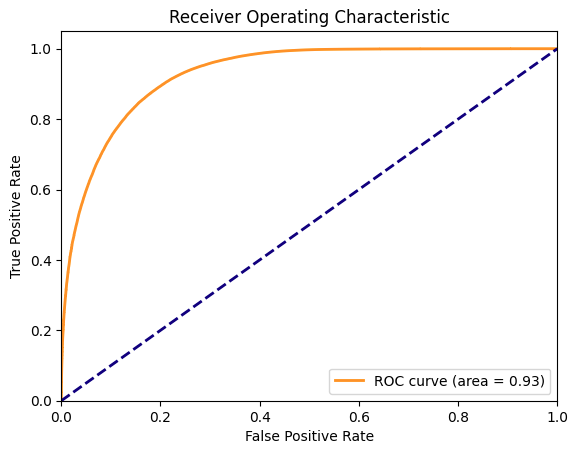